In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

ROOT = Path(r"D:\projects\f1-project")
laps = pd.read_csv(ROOT / "data/processed/laps_with_pit_flags_2023_2024_first5.csv")
pits = pd.read_csv(ROOT / "data/processed/pit_stops_2023_2024_first5.csv")

def to_seconds(text):
    """'1:39.019' -> 99.019. Works for 'm:ss.xxx', 'ss.xxx' and NaN."""
    total = 0.0
    for part in str(text).split(":"):
        total = total * 60 + float(part)
    return total

laps["lap_time_seconds"] = laps["lap_time"].apply(to_seconds)
laps["is_pit_lap"] = laps["is_pit_lap"].astype(bool)
print(laps.shape, pits.shape)
print(laps["lap_time_seconds"].describe())

(10050, 8) (374, 7)
count    10050.000000
mean       106.885037
std        109.822981
min         79.813000
25%         92.937250
50%         96.657500
75%        101.081750
max       2014.652000
Name: lap_time_seconds, dtype: float64


In [2]:
pits["duration_seconds"] = pits["duration"].apply(to_seconds)
print(pits["duration_seconds"].describe())

summary = pd.DataFrame({
    "stops": pits.groupby(["season", "round"]).size(),
    "missing_duration": pits.groupby(["season", "round"])["duration_seconds"].apply(lambda s: s.isna().sum()),
})
print(summary)

count    304.000000
mean      23.530148
std        4.561175
min       17.222000
25%       21.144000
50%       23.152000
75%       24.795500
max       48.938000
Name: duration_seconds, dtype: float64
              stops  missing_duration
season round                         
2023   1         50                 0
       2         24                 0
       3         65                49
       4         23                 0
       5         20                 0
2024   1         43                 1
       2         19                 1
       3         36                 0
       4         54                18
       5         40                 1


In [3]:
base = laps[(laps["lap"] > 1) & (~laps["is_pit_lap"])]
race_median = (base.groupby(["season", "round"])["lap_time_seconds"]
                   .median().rename("race_median").reset_index())
laps = laps.merge(race_median, on=["season", "round"], how="left")

laps["pace_ratio"] = laps["lap_time_seconds"] / laps["race_median"]
laps["odd_pace"] = (laps["pace_ratio"] > 1.07) | (laps["pace_ratio"] < 0.90)

print(laps["odd_pace"].sum(), "odd laps")
print(laps.groupby(["season", "round"])["odd_pace"].mean().round(3))

1103 odd laps
season  round
2023    1        0.081
        2        0.102
        3        0.242
        4        0.096
        5        0.034
2024    1        0.048
        2        0.080
        3        0.106
        4        0.101
        5        0.221
Name: odd_pace, dtype: float64


In [4]:
KEYS = ["season", "round", "driver_id"]

def add_delta(df, mask, ref_name, delta_name):
    """delta = lap time - that driver's median lap time in that race,
    where the median uses only laps selected by `mask`."""
    ref = (df[mask].groupby(KEYS)["lap_time_seconds"]
                   .median().rename(ref_name).reset_index())
    out = df.merge(ref, on=KEYS, how="left")
    out[delta_name] = out["lap_time_seconds"] - out[ref_name]
    return out

prelim_mask = (laps["lap"] > 1) & (~laps["is_pit_lap"]) & (~laps["odd_pace"])
laps = add_delta(laps, prelim_mask, "ref_prelim", "delta_prelim")
print(laps[["driver_id", "lap", "lap_time_seconds", "ref_prelim", "delta_prelim"]].head(8))

        driver_id  lap  lap_time_seconds  ref_prelim  delta_prelim
0  max_verstappen    1            99.019      97.582         1.437
1         leclerc    1           100.230      98.509         1.721
2           perez    1           101.063      97.400         3.663
3           sainz    1           101.659      98.210         3.449
4        hamilton    1           102.288      98.304         3.984
5         russell    1           102.662      98.085         4.577
6          alonso    1           103.608      97.931         5.677
7          bottas    1           104.154      98.129         6.025


In [5]:
frames = []
for offset in [-2, -1, 0, 1, 2]:
    t = pits[KEYS + ["lap"]].rename(columns={"lap": "pit_lap"})
    t["offset"] = offset
    t["lap"] = t["pit_lap"] + offset
    frames.append(t)
events = pd.concat(frames)

events = events.merge(laps[KEYS + ["lap", "delta_prelim"]], on=KEYS + ["lap"], how="left")
print(events.groupby("offset")["delta_prelim"].agg(["median", "mean", "count"]).round(2))

        median    mean  count
offset                       
-2        0.87   27.85    345
-1        1.14   17.15    349
 0        7.47  146.14    374
 1       21.96  149.94    374
 2        0.15   69.19    354


In [6]:
EXCLUDE_OFFSETS = [1]   # laps AFTER a stop to exclude; add -1 if the lap before looks slow in Cell 5

parts = []
for off in EXCLUDE_OFFSETS:
    t = pits[KEYS + ["lap"]].copy()
    t["lap"] = t["lap"] + off
    t["near_pit"] = True
    parts.append(t)
near = pd.concat(parts).drop_duplicates(KEYS + ["lap"])
laps = laps.merge(near, on=KEYS + ["lap"], how="left")
laps["near_pit"] = laps["near_pit"].notna()

laps["is_clean"] = ((laps["lap"] > 1) & (~laps["is_pit_lap"])
                    & (~laps["near_pit"]) & (~laps["odd_pace"]))

laps = add_delta(laps, laps["is_clean"], "ref_pace", "delta")

n_clean = (laps[laps["is_clean"]].groupby(KEYS).size().rename("n_clean").reset_index())
laps = laps.merge(n_clean, on=KEYS, how="left")
laps["n_clean"] = laps["n_clean"].fillna(0)
laps["usable_ref"] = laps["n_clean"] >= 10

print("rows:", len(laps))
print("lap 1:", (laps["lap"] == 1).sum(), "| pit laps:", laps["is_pit_lap"].sum(),
      "| near pit:", laps["near_pit"].sum(), "| odd pace:", laps["odd_pace"].sum())
print("clean:", laps["is_clean"].sum(), "| usable driver-races:", laps["usable_ref"].mean().round(3))
print(laps.loc[laps["is_clean"], "delta"].describe())

rows: 10050
lap 1: 196 | pit laps: 374 | near pit: 374 | odd pace: 1103
clean: 8682 | usable driver-races: 0.995
count    8682.000000
mean        0.063191
std         1.136846
min        -5.147000
25%        -0.666375
50%         0.000000
75%         0.717500
max         8.912500
Name: delta, dtype: float64


In [7]:
laps = laps.sort_values(KEYS + ["lap"]).reset_index(drop=True)

laps["last_stop_lap"] = laps["lap"].where(laps["is_pit_lap"])       # the lap number, only on pit laps
laps["last_stop_lap"] = laps.groupby(KEYS)["last_stop_lap"].shift(1)  # only stops strictly BEFORE this lap
laps["last_stop_lap"] = laps.groupby(KEYS)["last_stop_lap"].ffill()   # carry forward until the next stop
laps["last_stop_lap"] = laps["last_stop_lap"].fillna(0)               # no stop yet = stint started at lap 0

laps["stint_lap"] = laps["lap"] - laps["last_stop_lap"]

consecutive = laps.groupby(KEYS)["lap"].apply(lambda s: s.diff().dropna().eq(1).all())
print("driver-races with no missing laps:", consecutive.mean().round(3))

example = laps[(laps["driver_id"] == laps["driver_id"].iloc[0]) & (laps["round"] == 1) & (laps["season"] == 2023)]
print(example[["lap", "is_pit_lap", "last_stop_lap", "stint_lap"]].iloc[10:30])

driver-races with no missing laps: 1.0
    lap  is_pit_lap  last_stop_lap  stint_lap
10   11        True            0.0       11.0
11   12       False           11.0        1.0
12   13       False           11.0        2.0
13   14       False           11.0        3.0
14   15       False           11.0        4.0
15   16       False           11.0        5.0
16   17       False           11.0        6.0
17   18       False           11.0        7.0
18   19       False           11.0        8.0
19   20       False           11.0        9.0
20   21       False           11.0       10.0
21   22       False           11.0       11.0
22   23       False           11.0       12.0
23   24       False           11.0       13.0
24   25       False           11.0       14.0
25   26        True           11.0       15.0
26   27       False           26.0        1.0
27   28       False           26.0        2.0
28   29       False           26.0        3.0
29   30       False           26.0       

In [8]:
out_path = ROOT / "data/processed/laps_features_2023_2024_first5.csv"
laps.to_csv(out_path, index=False)

model_rows = laps[laps["is_clean"] & laps["usable_ref"]]
print("saved:", laps.shape, "| model-ready rows:", len(model_rows))

saved: (10050, 21) | model-ready rows: 8651


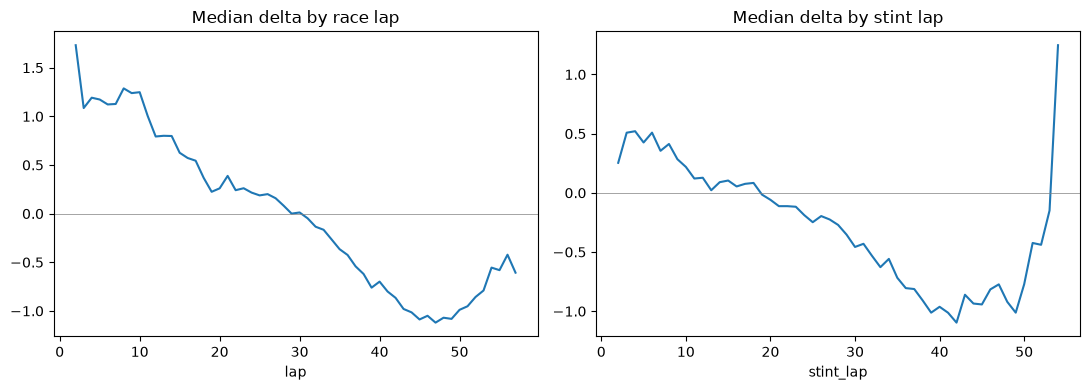

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
model_rows.groupby("lap")["delta"].median().plot(ax=ax[0], title="Median delta by race lap")
model_rows.groupby("stint_lap")["delta"].median().plot(ax=ax[1], title="Median delta by stint lap")
for a in ax: a.axhline(0, color="grey", lw=0.5)
plt.tight_layout(); plt.show()

In [10]:
long_laps = laps[laps["lap_time_seconds"] > 200]
print(long_laps.groupby(["season", "round", "lap"]).size())

season  round  lap
2023    3      8      17
               9       8
               54      3
               55     14
               56     11
               57     10
               58      2
2024    4      2      18
        5      27      1
dtype: int64


In [11]:
from sklearn.linear_model import Ridge
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.metrics import mean_absolute_error

laps["race"] = laps["season"].astype(str) + "-R" + laps["round"].astype(str)
laps["race_laps"] = laps.groupby("race")["lap"].transform("max")
laps["race_progress"] = laps["lap"] / laps["race_laps"]

model_rows = laps[laps["is_clean"] & laps["usable_ref"]].copy()
FEATURES = ["lap", "stint_lap", "race_progress"]
X, y, groups = model_rows[FEATURES], model_rows["delta"], model_rows["race"]

rows = []
for train_idx, test_idx in LeaveOneGroupOut().split(X, y, groups):
    model = Ridge(alpha=1.0).fit(X.iloc[train_idx], y.iloc[train_idx])
    pred = model.predict(X.iloc[test_idx])
    y_test = y.iloc[test_idx]
    rows.append({
        "race": groups.iloc[test_idx].iloc[0],
        "n": len(y_test),
        "mae_zero": mean_absolute_error(y_test, np.zeros(len(y_test))),
        "mae_ridge": mean_absolute_error(y_test, pred),
    })

results = pd.DataFrame(rows)
print(results.round(3))
print("overall zero :", ((results["mae_zero"] * results["n"]).sum() / results["n"].sum()).round(3))
print("overall ridge:", ((results["mae_ridge"] * results["n"]).sum() / results["n"].sum()).round(3))

      race     n  mae_zero  mae_ridge
0  2023-R1   919     0.926      0.652
1  2023-R2   829     0.875      0.513
2  2023-R3   741     0.800      0.637
3  2023-R4   840     0.779      0.423
4  2023-R5  1078     0.659      0.425
5  2024-R1  1024     0.902      0.527
6  2024-R2   811     0.936      0.617
7  2024-R3   865     0.763      0.553
8  2024-R4   774     1.129      0.679
9  2024-R5   770     0.861      0.680
overall zero : 0.857
overall ridge: 0.564


In [12]:
import pandas as pd
from pathlib import Path

DATA_DIR = Path("../data/processed")

# Load the original saved datasets
laps_full = pd.read_csv(
    DATA_DIR / "laps_with_pit_flags_2023_2024_first5.csv"
)

pits = pd.read_csv(
    DATA_DIR / "pit_stops_2023_2024_first5.csv"
)

print("FULL LAP DATA")
print("Total lap rows:", len(laps_full))
print("Pit flags in full dataset:", laps_full["is_pit_lap"].sum())

print("\nPIT-STOP DATA")
print("Total pit-stop records:", len(pits))
print("Unique pit-stop driver/lap combinations:",
      pits[["season", "round", "driver_id", "lap"]]
      .drop_duplicates().shape[0])

print("\nAFTER BROAD TIME FILTER")
time_seconds = laps_full["lap_time"].str.split(":").apply(
    lambda x: int(x[0]) * 60 + float(x[1])
)

pace_check = laps_full[time_seconds.between(50, 200)].copy()

print("Rows remaining:", len(pace_check))
print("Pit flags remaining:", pace_check["is_pit_lap"].sum())

print("\nPIT FLAGS REMOVED BY TIME FILTER")
print("Removed pit flags:",
      laps_full["is_pit_lap"].sum() - pace_check["is_pit_lap"].sum())

FULL LAP DATA
Total lap rows: 10050
Pit flags in full dataset: 374

PIT-STOP DATA
Total pit-stop records: 374
Unique pit-stop driver/lap combinations: 374

AFTER BROAD TIME FILTER
Rows remaining: 9966
Pit flags remaining: 330

PIT FLAGS REMOVED BY TIME FILTER
Removed pit flags: 44


In [13]:
# Identify pit laps removed by the broad time filter

removed_pit_laps = laps_full[
    (laps_full["is_pit_lap"] == True) &
    (~laps_full.index.isin(pace_check.index))
].copy()

print("Excluded pit-lap records:", len(removed_pit_laps))

display(
    removed_pit_laps[
        ["season", "round", "lap", "driver_id",
         "lap_time", "is_pit_lap"]
    ].head(20)
)

print("\nLap-time summary of excluded pit laps:")

removed_seconds = (
    removed_pit_laps["lap_time"]
    .str.split(":")
    .apply(lambda x: int(x[0]) * 60 + float(x[1]))
)

display(removed_seconds.describe())

Excluded pit-lap records: 44


,season,round,lap,driver_id,lap_time,is_pit_lap
2130,2023,3,8,max_verstappen,18:00.581,True
2131,2023,3,8,alonso,18:02.497,True
2132,2023,3,8,stroll,18:00.934,True
2133,2023,3,8,gasly,18:03.170,True
2134,2023,3,8,hulkenberg,18:01.953,True
2135,2023,3,8,russell,18:08.782,True
2136,2023,3,8,tsunoda,18:08.144,True
2137,2023,3,8,norris,18:11.111,True
2138,2023,3,8,piastri,18:12.634,True
2139,2023,3,8,sainz,18:19.710,True



Lap-time summary of excluded pit laps:


count      44.000000
mean     1196.439386
std       478.522883
min       393.824000
25%      1006.648500
50%      1085.657000
75%      1106.255750
max      2004.625000
Name: lap_time, dtype: float64

In [14]:
# Distribution of excluded pit laps by race

excluded_by_race = (
    removed_pit_laps
    .groupby(["season", "round"])
    .agg(
        excluded_records=("lap_time", "count"),
        affected_laps=("lap", "nunique"),
        affected_drivers=("driver_id", "nunique")
    )
    .reset_index()
    .sort_values("excluded_records", ascending=False)
)

display(excluded_by_race)

,season,round,excluded_records,affected_laps,affected_drivers
0,2023,3,44,4,17


In [15]:
# Examine all extreme lap records, not just pit laps

extreme_laps = laps_full.copy()

extreme_laps["lap_time_seconds"] = (
    extreme_laps["lap_time"]
    .str.split(":")
    .apply(lambda x: int(x[0]) * 60 + float(x[1]))
)

extreme_laps = extreme_laps[
    extreme_laps["lap_time_seconds"] > 200
]

display(
    extreme_laps.groupby(["season", "round"])
    .agg(
        extreme_records=("lap_time_seconds", "count"),
        affected_laps=("lap", "nunique"),
        affected_drivers=("driver_id", "nunique")
    )
    .reset_index()
)

,season,round,extreme_records,affected_laps,affected_drivers
0,2023,3,65,7,18
1,2024,4,18,1,18
2,2024,5,1,1,1


In [16]:
# Identify race laps with unusually large timing records

extreme_lap_distribution = (
    extreme_laps
    .groupby(["season", "round", "lap"])
    .agg(
        extreme_records=("driver_id", "count"),
        affected_drivers=("driver_id", "nunique"),
        median_extreme_time=("lap_time_seconds", "median")
    )
    .reset_index()
    .sort_values(
        ["season", "round", "lap"]
    )
)

display(extreme_lap_distribution)

,season,round,lap,extreme_records,affected_drivers,median_extreme_time
0,2023,3,8,17,17,1092.6340
1,2023,3,9,8,8,213.5740
2,2023,3,54,3,3,395.2140
3,2023,3,55,14,14,1005.0405
4,2023,3,56,11,11,220.5260
5,2023,3,57,10,10,1997.7145
6,2023,3,58,2,2,2013.2000
7,2024,4,2,18,18,1710.3010
8,2024,5,27,1,1,221.5200


In [17]:
# Inspect the existing feature dataset

features_path = DATA_DIR / "laps_features_2023_2024_first5.csv"

features = pd.read_csv(features_path)

print("Shape:", features.shape)
print("\nColumns:")
print(features.columns.tolist())

print("\nFirst five rows:")
display(features.head())

Shape: (10050, 21)

Columns:
['season', 'round', 'lap', 'driver_id', 'position', 'lap_time', 'is_pit_lap', 'lap_time_seconds', 'race_median', 'pace_ratio', 'odd_pace', 'ref_prelim', 'delta_prelim', 'near_pit', 'is_clean', 'ref_pace', 'delta', 'n_clean', 'usable_ref', 'last_stop_lap', 'stint_lap']

First five rows:


,season,round,lap,driver_id,position,lap_time,is_pit_lap,lap_time_seconds,race_median,pace_ratio,...,ref_prelim,delta_prelim,near_pit,is_clean,ref_pace,delta,n_clean,usable_ref,last_stop_lap,stint_lap
0,2023,1,1,albon,12,1:46.453,False,106.453,98.46,1.081180,...,98.1675,8.2855,False,False,98.1675,8.2855,50.0,True,0.0,1.0
1,2023,1,2,albon,12,1:40.430,False,100.430,98.46,1.020008,...,98.1675,2.2625,False,True,98.1675,2.2625,50.0,True,0.0,2.0
2,2023,1,3,albon,12,1:40.143,False,100.143,98.46,1.017093,...,98.1675,1.9755,False,True,98.1675,1.9755,50.0,True,0.0,3.0
3,2023,1,4,albon,11,1:39.761,False,99.761,98.46,1.013213,...,98.1675,1.5935,False,True,98.1675,1.5935,50.0,True,0.0,4.0
4,2023,1,5,albon,11,1:40.606,False,100.606,98.46,1.021796,...,98.1675,2.4385,False,True,98.1675,2.4385,50.0,True,0.0,5.0


In [18]:
# Inspect existing cleaning and feature flags

print("Total rows:", len(features))

print("\nClean lap counts:")
print(features["is_clean"].value_counts(dropna=False))

print("\nUnusual pace counts:")
print(features["odd_pace"].value_counts(dropna=False))

print("\nNear pit counts:")
print(features["near_pit"].value_counts(dropna=False))

print("\nUsable reference counts:")
print(features["usable_ref"].value_counts(dropna=False))

print("\nMissing values:")
display(
    features[
        ["race_median", "pace_ratio", "ref_pace",
         "delta", "n_clean", "stint_lap"]
    ].isna().sum()
)

Total rows: 10050

Clean lap counts:
is_clean
True     8682
False    1368
Name: count, dtype: int64

Unusual pace counts:
odd_pace
False    8947
True     1103
Name: count, dtype: int64

Near pit counts:
near_pit
False    9676
True      374
Name: count, dtype: int64

Usable reference counts:
usable_ref
True     9997
False      53
Name: count, dtype: int64

Missing values:


race_median    0
pace_ratio     0
ref_pace       1
delta          1
n_clean        0
stint_lap      0
dtype: int64

In [19]:

# DAY 4 — STEP 1: BUILD A PROSPECTIVE MODELLING DATASET

# 1. Start with the original lap data.
# Keep only columns needed for this first modelling experiment.

model_base = laps[
    [
        "season",
        "round",
        "driver_id",
        "lap",
        "lap_time_seconds",
        "is_pit_lap",
        "stint_lap"
    ]
].copy()

# 2. Apply the broad lap-time plausibility filter.
model_base = model_base[
    model_base["lap_time_seconds"].between(50, 200)
].copy()

# 3. Exclude lap 1 (standing start).
model_base = model_base[model_base["lap"] > 1].copy()

# 4. Mark the lap immediately after each recorded pit stop.
# This is based on recorded historical pit-stop information.

near_pit_laps = pits[KEYS + ["lap"]].copy()
near_pit_laps["lap"] = near_pit_laps["lap"] + 1
near_pit_laps["near_pit"] = True

near_pit_laps = near_pit_laps.drop_duplicates(
    subset=KEYS + ["lap"]
)

model_base = model_base.merge(
    near_pit_laps,
    on=KEYS + ["lap"],
    how="left"
)

model_base["near_pit"] = (
    model_base["near_pit"].fillna(False)
)

# 5. Exclude recorded pit-stop laps and the following laps.
model_base = model_base[
    (~model_base["is_pit_lap"]) &
    (~model_base["near_pit"])
].copy()

# 6. Sort laps chronologically within each driver-race.
model_base = model_base.sort_values(
    KEYS + ["lap"]
).reset_index(drop=True)

# 7. Count eligible laps for each driver-race.
model_base["eligible_order"] = (
    model_base.groupby(KEYS).cumcount() + 1
)

# 8. Calculate reference pace using ONLY the first five
# eligible laps of each driver-race.

reference_pace = (
    model_base[model_base["eligible_order"] <= 5]
    .groupby(KEYS)["lap_time_seconds"]
    .mean()
    .rename("reference_pace")
    .reset_index()
)

# 9. Keep subsequent laps as prediction targets.
model_df = model_base[
    model_base["eligible_order"] > 5
].copy()

model_df = model_df.merge(
    reference_pace,
    on=KEYS,
    how="inner"
)

# 10. Calculate the target: deviation from observed reference pace.
model_df["delta"] = (
    model_df["lap_time_seconds"] -
    model_df["reference_pace"]
)

print("PROSPECTIVE MODELLING DATASET")
print("-" * 45)

print("Eligible laps before reference split:", len(model_base))
print("Driver-race groups:", model_base.groupby(KEYS).ngroups)
print("Prediction rows:", len(model_df))
print("Unique races:", model_df.groupby(["season", "round"]).ngroups)

print("\nReference pace check:")
print(reference_pace["reference_pace"].describe())

print("\nPrediction target check:")
print(model_df["delta"].describe())

print("\nMissing values:")
print(
    model_df[
        ["lap", "stint_lap", "reference_pace", "delta"]
    ].isna().sum()
)

print("\nSample prediction rows:")
display(
    model_df[
        [
            "season",
            "round",
            "driver_id",
            "lap",
            "stint_lap",
            "reference_pace",
            "lap_time_seconds",
            "delta"
        ]
    ].head(10)
)


PROSPECTIVE MODELLING DATASET
---------------------------------------------
Eligible laps before reference split: 9143
Driver-race groups: 195
Prediction rows: 8172
Unique races: 10

Reference pace check:
count    195.000000
mean      98.758291
std        7.120467
min       82.648000
25%       95.246100
50%       98.582400
75%      102.970600
max      112.136000
Name: reference_pace, dtype: float64

Prediction target check:
count    8172.000000
mean       -2.130534
std         9.776644
min       -22.078000
25%        -2.744300
50%        -1.651500
75%        -0.738400
max        78.977400
Name: delta, dtype: float64

Missing values:
lap               0
stint_lap         0
reference_pace    0
delta             0
dtype: int64

Sample prediction rows:


C:\Users\HP\AppData\Local\Temp\ipykernel_1952\2406336478.py:44: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  model_base["near_pit"].fillna(False)


,season,round,driver_id,lap,stint_lap,reference_pace,lap_time_seconds,delta
0,2023,1,albon,7,7.0,100.3368,100.646,0.3092
1,2023,1,albon,8,8.0,100.3368,100.918,0.5812
2,2023,1,albon,9,9.0,100.3368,100.969,0.6322
3,2023,1,albon,10,10.0,100.3368,101.119,0.7822
4,2023,1,albon,13,2.0,100.3368,98.649,-1.6878
5,2023,1,albon,14,3.0,100.3368,98.472,-1.8648
6,2023,1,albon,15,4.0,100.3368,99.158,-1.1788
7,2023,1,albon,16,5.0,100.3368,99.253,-1.0838
8,2023,1,albon,17,6.0,100.3368,99.094,-1.2428
9,2023,1,albon,18,7.0,100.3368,99.049,-1.2878


In [20]:

# DAY 4 — STEP 2: CHECK TARGET OUTLIERS AND STINT EFFECTS

print("1. TARGET OUTLIER COUNTS")
print("-" * 45)

for threshold in [5, 10, 20, 30]:
    count = (model_df["delta"].abs() > threshold).sum()
    print(f"Rows with absolute delta > {threshold}s: {count}")

print("\n2. LARGEST POSITIVE DELTAS")
print("-" * 45)

display(
    model_df.nlargest(15, "delta")[
        [
            "season", "round", "driver_id", "lap",
            "stint_lap", "reference_pace",
            "lap_time_seconds", "delta"
        ]
    ]
)

print("\n3. LARGEST NEGATIVE DELTAS")
print("-" * 45)

display(
    model_df.nsmallest(10, "delta")[
        [
            "season", "round", "driver_id", "lap",
            "stint_lap", "reference_pace",
            "lap_time_seconds", "delta"
        ]
    ]
)

print("\n4. TARGET DISTRIBUTION BY RACE")
print("-" * 45)

race_target_summary = (
    model_df.groupby(["season", "round"])["delta"]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .round(2)
)

display(race_target_summary)

print("\n5. TARGET DISTRIBUTION BY STINT LAP")
print("-" * 45)

stint_summary = (
    model_df.groupby("stint_lap")["delta"]
    .agg(["count", "mean", "median", "std"])
    .head(20)
    .round(2)
)

display(stint_summary)


1. TARGET OUTLIER COUNTS
---------------------------------------------
Rows with absolute delta > 5s: 1776
Rows with absolute delta > 10s: 1443
Rows with absolute delta > 20s: 436
Rows with absolute delta > 30s: 215

2. LARGEST POSITIVE DELTAS
---------------------------------------------


,season,round,driver_id,lap,stint_lap,reference_pace,lap_time_seconds,delta
5451,2024,2,norris,8,8.0,95.0276,174.005,78.9774
5241,2024,2,hamilton,8,8.0,95.3162,173.631,78.3148
5283,2024,2,hulkenberg,8,8.0,96.5140,170.478,73.9640
5783,2024,2,zhou,8,8.0,97.1214,166.499,69.3776
5408,2024,2,max_verstappen,9,2.0,93.9266,160.995,67.0684
5452,2024,2,norris,9,9.0,95.0276,161.791,66.7634
1320,2023,2,perez,20,2.0,95.1760,160.799,65.6230
5533,2024,2,perez,9,2.0,94.1086,158.896,64.7874
5366,2024,2,leclerc,9,2.0,94.5134,158.648,64.1346
865,2023,2,alonso,20,2.0,95.3898,159.344,63.9542



3. LARGEST NEGATIVE DELTAS
---------------------------------------------


,season,round,driver_id,lap,stint_lap,reference_pace,lap_time_seconds,delta
1963,2023,3,max_verstappen,49,41.0,102.4200,80.342,-22.0780
1828,2023,3,hamilton,49,41.0,102.6008,80.613,-21.9878
1964,2023,3,max_verstappen,50,42.0,102.4200,80.471,-21.9490
1832,2023,3,hamilton,53,45.0,102.6008,80.652,-21.9488
1830,2023,3,hamilton,51,43.0,102.6008,80.682,-21.9188
1831,2023,3,hamilton,52,44.0,102.6008,80.741,-21.8598
2200,2023,3,sainz,53,45.0,102.2568,80.467,-21.7898
1965,2023,3,max_verstappen,51,43.0,102.4200,80.632,-21.7880
1826,2023,3,hamilton,47,39.0,102.6008,80.816,-21.7848
1827,2023,3,hamilton,48,40.0,102.6008,80.850,-21.7508



4. TARGET DISTRIBUTION BY RACE
---------------------------------------------


count   mean  median    std    min    max
season round                                           
2023   1        835  -1.14   -1.58   3.49  -6.91  27.92
       2        775   1.00   -1.38  10.53  -4.48  65.62
       3        768 -15.31  -18.33   6.80 -22.08  21.02
       4        795   0.72   -1.51   9.49  -4.95  58.95
       5        978  -1.31   -1.29   0.85  -3.68   2.05
2024   1        924  -1.38   -1.30   1.10  -4.24   2.89
       2        748   0.46   -1.38  10.68  -4.91  78.98
       3        812   0.03   -0.94   5.70  -3.04  44.96
       4        707 -11.93  -11.55   3.02 -18.23  -5.18
       5        830   5.50   -1.13  14.88  -5.39  56.69


5. TARGET DISTRIBUTION BY STINT LAP
---------------------------------------------


,count,mean,median,std
stint_lap,,,,
2.0,290,5.13,-1.77,19.95
3.0,294,1.22,-1.66,14.98
4.0,295,-0.75,-1.55,12.01
5.0,296,-0.16,-1.60,13.68
6.0,295,-0.89,-1.59,12.09
7.0,445,-0.67,-0.93,10.35
8.0,423,-0.27,-0.90,12.12
9.0,404,-1.08,-1.09,10.37
10.0,386,-0.94,-1.00,7.37


In [21]:

# DAY 4 — STEP 3: DETECT RACE-WIDE TIMING ANOMALIES

race_lap_check = (
    model_df
    .groupby(["season", "round", "lap"])["delta"]
    .agg(
        drivers="count",
        median_delta="median",
        mean_delta="mean",
        min_delta="min",
        max_delta="max"
    )
    .reset_index()
)

# Focus on laps with at least 5 drivers represented
race_lap_check = race_lap_check[
    race_lap_check["drivers"] >= 5
].copy()

# Flag laps where the cross-driver median shift is unusually large
race_lap_check["possible_event"] = (
    race_lap_check["median_delta"].abs() > 5
)

print("POSSIBLE RACE-WIDE ABNORMAL LAPS")
print("-" * 55)

display(
    race_lap_check[
        race_lap_check["possible_event"]
    ]
    .sort_values(
        by="median_delta",
        key=lambda x: x.abs(),
        ascending=False
    )
    .round(2)
)

print("\nCOUNT OF POSSIBLE EVENT LAPS BY RACE")
print("-" * 55)

display(
    race_lap_check.groupby(["season", "round"])
    .agg(
        total_laps=("lap", "count"),
        possible_event_laps=("possible_event", "sum")
    )
    .reset_index()
)


POSSIBLE RACE-WIDE ABNORMAL LAPS
-------------------------------------------------------


,season,round,lap,drivers,median_delta,mean_delta,min_delta,max_delta,possible_event
64,2023,2,20,18,54.81,53.63,30.72,65.62,True
290,2024,2,9,18,54.36,54.75,33.47,67.07,True
449,2024,5,26,18,46.94,45.90,29.23,56.69,True
451,2024,5,28,17,46.45,45.62,35.33,50.80,True
147,2023,4,13,18,46.31,46.90,35.72,58.95,True
...,...,...,...,...,...,...,...,...,...
389,2024,4,13,14,-9.84,-10.06,-16.38,-5.18,True
392,2024,4,16,13,-9.78,-9.91,-13.89,-6.76,True
393,2024,4,17,15,-9.77,-10.66,-15.00,-6.85,True
391,2024,4,15,15,-9.51,-9.93,-15.35,-6.27,True



COUNT OF POSSIBLE EVENT LAPS BY RACE
-------------------------------------------------------


,season,round,total_laps,possible_event_laps
0,2023,1,51,1
1,2023,2,44,4
2,2023,3,46,42
3,2023,4,45,4
4,2023,5,51,0
5,2024,1,51,0
6,2024,2,42,1
7,2024,3,52,3
8,2024,4,46,46
9,2024,5,50,11


In [22]:

# DAY 4 — STEP 4: REMOVE IDENTIFIED RACE-WIDE ANOMALIES

# Races with widespread reference-pace distortion
exclude_races = [
    (2023, 3),
    (2024, 4)
]

# Individual race-lap groups flagged by our diagnostic
anomaly_laps = race_lap_check.loc[
    race_lap_check["possible_event"],
    ["season", "round", "lap"]
].drop_duplicates()

# Work on a copy
model_df_clean = model_df.copy()

# Exclude the two heavily distorted races
race_mask = model_df_clean.apply(
    lambda row: (row["season"], row["round"]) not in exclude_races,
    axis=1
)

model_df_clean = model_df_clean[race_mask].copy()

# Exclude individual anomalous race-lap groups
model_df_clean = model_df_clean.merge(
    anomaly_laps.assign(possible_event=True),
    on=["season", "round", "lap"],
    how="left"
)

model_df_clean["possible_event"] = (
    model_df_clean["possible_event"].fillna(False).astype(bool)
)

model_df_clean = model_df_clean[
    ~model_df_clean["possible_event"]
].copy()

# Final checks
print("CLEAN MODELLING DATASET")
print("-" * 45)

print("Original prediction rows:", len(model_df))
print("Rows after anomaly filtering:", len(model_df_clean))
print("Rows removed:", len(model_df) - len(model_df_clean))

print(
    "Remaining races:",
    model_df_clean.groupby(["season", "round"]).ngroups
)

print(
    "Remaining driver-race groups:",
    model_df_clean.groupby(KEYS).ngroups
)

print("\nTarget distribution:")
print(model_df_clean["delta"].describe().round(3))

print("\nRemaining race-wise target summary:")
display(
    model_df_clean.groupby(["season", "round"])["delta"]
    .agg(["count", "mean", "median", "std", "min", "max"])
    .round(2)
)

print("\nRemaining missing values:")
print(model_df_clean[["reference_pace", "delta", "stint_lap"]].isna().sum())


CLEAN MODELLING DATASET
---------------------------------------------
Original prediction rows: 8172
Rows after anomaly filtering: 6358
Rows removed: 1814
Remaining races: 8
Remaining driver-race groups: 156

Target distribution:
count    6358.000
mean       -1.276
std         2.591
min        -6.906
25%        -2.139
50%        -1.391
75%        -0.692
max        78.977
Name: delta, dtype: float64

Remaining race-wise target summary:


C:\Users\HP\AppData\Local\Temp\ipykernel_1952\2305217764.py:34: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  model_df_clean["possible_event"].fillna(False).astype(bool)


count  mean  median   std   min    max
season round                                        
2023   1        823 -1.42   -1.60  2.26 -6.91  27.92
       2        725 -1.36   -1.49  2.41 -4.48  54.55
       4        741 -1.49   -1.60  1.08 -4.95   4.63
       5        978 -1.31   -1.29  0.85 -3.68   2.05
2024   1        924 -1.38   -1.30  1.10 -4.24   2.89
       2        730 -0.88   -1.40  6.35 -4.91  78.98
       3        775 -1.05   -1.00  1.16 -3.04   7.28
       5        662 -1.27   -1.44  1.18 -5.39  12.10


Remaining missing values:
reference_pace    0
delta             0
stint_lap         0
dtype: int64


In [23]:

# DAY 4 — STEP 5: INVESTIGATE REMAINING EXTREME TARGETS

print("ROWS WITH DELTA ABOVE 10 SECONDS")
print("-" * 50)

extreme_rows = model_df_clean[
    model_df_clean["delta"].abs() > 10
].copy()

print("Extreme rows:", len(extreme_rows))

display(
    extreme_rows.sort_values(
        "delta",
        ascending=False
    )[
        [
            "season", "round", "driver_id",
            "lap", "stint_lap",
            "reference_pace",
            "lap_time_seconds", "delta"
        ]
    ].head(30)
)

print("\nEXTREME ROWS GROUPED BY RACE AND LAP")
print("-" * 50)

extreme_lap_summary = (
    extreme_rows.groupby(["season", "round", "lap"])
    .agg(
        affected_drivers=("driver_id", "nunique"),
        median_delta=("delta", "median"),
        mean_delta=("delta", "mean"),
        max_delta=("delta", "max")
    )
    .reset_index()
    .sort_values("max_delta", ascending=False)
)

display(extreme_lap_summary.head(30))

print("\nCOUNTS BY ABSOLUTE DELTA THRESHOLD")
print("-" * 50)

for threshold in [5, 10, 15, 20, 30]:
    print(
        f">{threshold}s:",
        (model_df_clean["delta"].abs() > threshold).sum()
    )


ROWS WITH DELTA ABOVE 10 SECONDS
--------------------------------------------------
Extreme rows: 16


,season,round,driver_id,lap,stint_lap,reference_pace,lap_time_seconds,delta
4683,2024,2,norris,8,8.0,95.0276,174.005,78.9774
4473,2024,2,hamilton,8,8.0,95.3162,173.631,78.3148
4515,2024,2,hulkenberg,8,8.0,96.5140,170.478,73.9640
5015,2024,2,zhou,8,8.0,97.1214,166.499,69.3776
853,2023,2,albon,27,10.0,97.4012,151.949,54.5478
5014,2024,2,zhou,7,7.0,97.1214,132.760,35.6386
4514,2024,2,hulkenberg,7,7.0,96.5140,129.724,33.2100
4472,2024,2,hamilton,7,7.0,95.3162,128.128,32.8118
4682,2024,2,norris,7,7.0,95.0276,127.025,31.9974
505,2023,1,ocon,40,8.0,100.1022,128.023,27.9208



EXTREME ROWS GROUPED BY RACE AND LAP
--------------------------------------------------


,season,round,lap,affected_drivers,median_delta,mean_delta,max_delta
4,2024,2,8,4,76.1394,75.15845,78.9774
2,2023,2,27,1,54.5478,54.54780,54.5478
3,2024,2,7,4,33.0109,33.41445,35.6386
1,2023,1,40,5,12.6778,18.12256,27.9208
0,2023,1,13,1,21.2286,21.22860,21.2286
5,2024,5,33,1,12.0988,12.09880,12.0988



COUNTS BY ABSOLUTE DELTA THRESHOLD
--------------------------------------------------
>5s: 26
>10s: 16
>15s: 12
>20s: 12
>30s: 9


In [24]:

# DAY 4 — STEP 6: FINAL DATASET + ZERO-DELTA BASELINE

# 1. Preserve the cleaned dataset before final outlier exclusion
model_df_before_final_filter = model_df_clean.copy()

# 2. Exclude extreme target deviations
model_df_final = model_df_clean[
    model_df_clean["delta"].abs() <= 10
].copy()

# 3. Calculate the zero-delta baseline
# Prediction: every future lap stays at the driver's reference pace.

model_df_final["baseline_prediction"] = 0.0

model_df_final["baseline_absolute_error"] = (
    model_df_final["delta"] -
    model_df_final["baseline_prediction"]
).abs()

# 4. Calculate overall baseline metrics
baseline_mae = model_df_final[
    "baseline_absolute_error"
].mean()

baseline_rmse = (
    (model_df_final["delta"] ** 2).mean()
) ** 0.5

print("FINAL MODELLING DATASET")
print("-" * 45)

print("Rows before final filter:", len(model_df_clean))
print("Rows after final filter:", len(model_df_final))
print("Extreme rows excluded:", len(model_df_clean) - len(model_df_final))

print("Races:", model_df_final.groupby(["season", "round"]).ngroups)
print("Driver-race groups:", model_df_final.groupby(KEYS).ngroups)

print("\nFINAL TARGET DISTRIBUTION")
print(model_df_final["delta"].describe().round(3))

print("\nZERO-DELTA BASELINE")
print("-" * 45)
print(f"Baseline MAE:  {baseline_mae:.4f} seconds")
print(f"Baseline RMSE: {baseline_rmse:.4f} seconds")

print("\nMISSING VALUES")
print(
    model_df_final[
        ["reference_pace", "delta", "stint_lap"]
    ].isna().sum()
)


FINAL MODELLING DATASET
---------------------------------------------
Rows before final filter: 6358
Rows after final filter: 6342
Extreme rows excluded: 16
Races: 8
Driver-race groups: 156

FINAL TARGET DISTRIBUTION
count    6342.000
mean       -1.375
std         1.149
min        -6.906
25%        -2.141
50%        -1.394
75%        -0.700
max         7.282
Name: delta, dtype: float64

ZERO-DELTA BASELINE
---------------------------------------------
Baseline MAE:  1.5226 seconds
Baseline RMSE: 1.7919 seconds

MISSING VALUES
reference_pace    0
delta             0
stint_lap         0
dtype: int64


In [25]:
# DAY 4 — STEP 7: RIDGE REGRESSION
# Leave-One-Race-Out validation

import numpy as np
import pandas as pd

from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.metrics import mean_absolute_error, mean_squared_error

# 1. Select features and target
FEATURES = ["lap", "stint_lap"]
TARGET = "delta"

X = model_df_final[FEATURES].copy()
y = model_df_final[TARGET].copy()

# Each race gets a unique group identifier
race_groups = (
    model_df_final["season"].astype(str)
    + "_"
    + model_df_final["round"].astype(str)
)

# 2. Define the model
# Scaling is fitted separately inside each training fold.
ridge_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("ridge", Ridge(alpha=1.0))
])

# 3. Leave one complete race out at a time
logo = LeaveOneGroupOut()

results = []

for train_idx, test_idx in logo.split(X, y, groups=race_groups):

    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

    test_race = race_groups.iloc[test_idx].iloc[0]

    # Train only on the other races
    ridge_pipeline.fit(X_train, y_train)

    # Predict the held-out race
    ridge_predictions = ridge_pipeline.predict(X_test)

    # Zero-delta baseline predicts that every lap matches
    # the driver's reference pace.
    baseline_predictions = np.zeros(len(y_test))

    results.append({
        "race": test_race,
        "rows": len(y_test),

        "baseline_MAE": mean_absolute_error(
            y_test, baseline_predictions
        ),
        "ridge_MAE": mean_absolute_error(
            y_test, ridge_predictions
        ),

        "baseline_RMSE": np.sqrt(
            mean_squared_error(y_test, baseline_predictions)
        ),
        "ridge_RMSE": np.sqrt(
            mean_squared_error(y_test, ridge_predictions)
        )
    })

# 4. Display race-wise performance
ridge_results = pd.DataFrame(results).sort_values("race")

print("RACE-WISE MODEL PERFORMANCE")
print("-" * 75)
display(ridge_results.round(4))

# 5. Calculate overall held-out performance
# Every row appears in exactly one held-out test fold.
all_ridge_predictions = np.zeros(len(y))

for train_idx, test_idx in logo.split(X, y, groups=race_groups):
    ridge_pipeline.fit(X.iloc[train_idx], y.iloc[train_idx])
    all_ridge_predictions[test_idx] = ridge_pipeline.predict(X.iloc[test_idx])

baseline_mae = mean_absolute_error(y, np.zeros(len(y)))
baseline_rmse = np.sqrt(mean_squared_error(y, np.zeros(len(y))))

ridge_mae = mean_absolute_error(y, all_ridge_predictions)
ridge_rmse = np.sqrt(mean_squared_error(y, all_ridge_predictions))

print("\nOVERALL HELD-OUT PERFORMANCE")
print("-" * 45)
print(f"Baseline MAE: {baseline_mae:.4f} seconds")
print(f"Ridge MAE:    {ridge_mae:.4f} seconds")
print(f"Baseline RMSE:{baseline_rmse:.4f} seconds")
print(f"Ridge RMSE:   {ridge_rmse:.4f} seconds")

mae_improvement = (
    (baseline_mae - ridge_mae) / baseline_mae
) * 100

rmse_improvement = (
    (baseline_rmse - ridge_rmse) / baseline_rmse
) * 100

print(f"\nMAE improvement:  {mae_improvement:.2f}%")
print(f"RMSE improvement: {rmse_improvement:.2f}%")

RACE-WISE MODEL PERFORMANCE
---------------------------------------------------------------------------


,race,rows,baseline_MAE,ridge_MAE,baseline_RMSE,ridge_RMSE
0,2023_1,817,1.7454,0.7852,2.0553,1.0160
1,2023_2,724,1.6156,0.7815,1.8881,1.0017
2,2023_4,741,1.6375,0.6734,1.8384,0.9380
3,2023_5,978,1.3558,0.4691,1.5589,0.6156
4,2024_1,924,1.4962,0.5798,1.7669,0.7519
5,2024_2,722,1.6537,0.8211,1.9792,1.1001
6,2024_3,775,1.2786,0.6297,1.5666,1.0978
7,2024_5,661,1.4429,0.6494,1.6659,0.8180



OVERALL HELD-OUT PERFORMANCE
---------------------------------------------
Baseline MAE: 1.5226 seconds
Ridge MAE:    0.6640 seconds
Baseline RMSE:1.7919 seconds
Ridge RMSE:   0.9197 seconds

MAE improvement:  56.39%
RMSE improvement: 48.67%


In [26]:
# DAY 4 — STEP 8: TRAINING-MEAN BASELINE VS RIDGE

from sklearn.model_selection import LeaveOneGroupOut
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

logo = LeaveOneGroupOut()

mean_baseline_predictions = np.zeros(len(y))
ridge_oof_predictions = np.zeros(len(y))

for train_idx, test_idx in logo.split(X, y, groups=race_groups):

    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

    # Stronger baseline: training races' average delta
    training_mean = y_train.mean()
    mean_baseline_predictions[test_idx] = training_mean

    # Ridge model
    ridge_pipeline.fit(X_train, y_train)
    ridge_oof_predictions[test_idx] = ridge_pipeline.predict(X_test)

# Compare all three approaches on exactly the same held-out rows
comparison = pd.DataFrame({
    "zero_delta": np.zeros(len(y)),
    "training_mean": mean_baseline_predictions,
    "ridge": ridge_oof_predictions
})

print("OVERALL COMPARISON")
print("-" * 55)

for model_name in comparison.columns:
    mae = mean_absolute_error(y, comparison[model_name])
    rmse = np.sqrt(mean_squared_error(y, comparison[model_name]))

    print(f"{model_name:15s} MAE: {mae:.4f} | RMSE: {rmse:.4f}")

# Race-wise comparison
comparison_by_race = []

for race in race_groups.unique():

    mask = (race_groups == race).to_numpy()
    actual = y.to_numpy()[mask]

    comparison_by_race.append({
        "race": race,
        "zero_delta_MAE": mean_absolute_error(
            actual, comparison["zero_delta"].to_numpy()[mask]
        ),
        "training_mean_MAE": mean_absolute_error(
            actual, comparison["training_mean"].to_numpy()[mask]
        ),
        "ridge_MAE": mean_absolute_error(
            actual, comparison["ridge"].to_numpy()[mask]
        )
    })

comparison_by_race = pd.DataFrame(comparison_by_race).sort_values("race")

print("\nRACE-WISE MAE COMPARISON")
display(comparison_by_race.round(4))

OVERALL COMPARISON
-------------------------------------------------------
zero_delta      MAE: 1.5226 | RMSE: 1.7919
training_mean   MAE: 0.8828 | RMSE: 1.1514
ridge           MAE: 0.6640 | RMSE: 0.9197

RACE-WISE MAE COMPARISON


,race,zero_delta_MAE,training_mean_MAE,ridge_MAE
0,2023_1,1.7454,1.0515,0.7852
1,2023_2,1.6156,0.9885,0.7815
2,2023_4,1.6375,0.7841,0.6734
3,2023_5,1.3558,0.7012,0.4691
4,2024_1,1.4962,0.9014,0.5798
5,2024_2,1.6537,0.9695,0.8211
6,2024_3,1.2786,0.8887,0.6297
7,2024_5,1.4429,0.8102,0.6494


In [27]:
# DAY 4 — STEP 9: NESTED RIDGE HYPERPARAMETER TUNING

import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Candidate regularisation strengths
alpha_values = [0.01, 0.1, 1.0, 10.0, 100.0]

outer_cv = LeaveOneGroupOut()
inner_cv = LeaveOneGroupOut()

tuned_predictions = np.zeros(len(y))
selected_alphas = []
tuning_results = []

# Outer loop: one race is held out for final testing
for outer_train_idx, outer_test_idx in outer_cv.split(
    X, y, groups=race_groups
):

    X_outer_train = X.iloc[outer_train_idx]
    y_outer_train = y.iloc[outer_train_idx]
    groups_outer_train = race_groups.iloc[outer_train_idx]

    X_outer_test = X.iloc[outer_test_idx]
    y_outer_test = y.iloc[outer_test_idx]

    test_race = race_groups.iloc[outer_test_idx].iloc[0]

    # Inner loop: choose alpha using only the outer training races
    alpha_scores = []

    for alpha in alpha_values:

        inner_predictions = np.zeros(len(y_outer_train))

        for inner_train_idx, inner_val_idx in inner_cv.split(
            X_outer_train,
            y_outer_train,
            groups=groups_outer_train
        ):

            model = Pipeline([
                ("scaler", StandardScaler()),
                ("ridge", Ridge(alpha=alpha))
            ])

            model.fit(
                X_outer_train.iloc[inner_train_idx],
                y_outer_train.iloc[inner_train_idx]
            )

            inner_predictions[inner_val_idx] = model.predict(
                X_outer_train.iloc[inner_val_idx]
            )

        inner_mae = mean_absolute_error(
            y_outer_train,
            inner_predictions
        )

        alpha_scores.append((alpha, inner_mae))

    # Select alpha with the lowest inner-validation MAE
    best_alpha, best_inner_mae = min(
        alpha_scores,
        key=lambda item: item[1]
    )

    selected_alphas.append(best_alpha)

    # Refit on all outer training races
    final_model = Pipeline([
        ("scaler", StandardScaler()),
        ("ridge", Ridge(alpha=best_alpha))
    ])

    final_model.fit(X_outer_train, y_outer_train)

    # Predict the untouched outer test race
    tuned_predictions[outer_test_idx] = final_model.predict(
        X_outer_test
    )

    tuning_results.append({
        "held_out_race": test_race,
        "selected_alpha": best_alpha,
        "inner_validation_MAE": best_inner_mae,
        "test_MAE": mean_absolute_error(
            y_outer_test,
            tuned_predictions[outer_test_idx]
        ),
        "test_RMSE": np.sqrt(mean_squared_error(
            y_outer_test,
            tuned_predictions[outer_test_idx]
        ))
    })

# Results
tuning_results = pd.DataFrame(tuning_results).sort_values(
    "held_out_race"
)

print("NESTED CROSS-VALIDATION RESULTS")
print("-" * 65)
display(tuning_results.round(4))

# Overall performance
tuned_mae = mean_absolute_error(y, tuned_predictions)
tuned_rmse = np.sqrt(mean_squared_error(y, tuned_predictions))

print("\nOVERALL PERFORMANCE")
print("-" * 45)
print(f"Zero-delta baseline MAE: {baseline_mae:.4f}")
print(f"Training-mean MAE:      {mean_absolute_error(y, mean_baseline_predictions):.4f}")
print(f"Fixed Ridge (alpha=1) MAE: {ridge_mae:.4f}")
print(f"Tuned Ridge MAE:        {tuned_mae:.4f}")

print(f"\nZero-delta baseline RMSE: {baseline_rmse:.4f}")
print(f"Fixed Ridge RMSE:        {ridge_rmse:.4f}")
print(f"Tuned Ridge RMSE:        {tuned_rmse:.4f}")

print("\nALPHA SELECTION FREQUENCY")
print(pd.Series(selected_alphas).value_counts().sort_index())

NESTED CROSS-VALIDATION RESULTS
-----------------------------------------------------------------


,held_out_race,selected_alpha,inner_validation_MAE,test_MAE,test_RMSE
0,2023_1,100.0,0.6425,0.7904,1.0222
1,2023_2,100.0,0.6533,0.7804,1.0016
2,2023_4,100.0,0.6664,0.6675,0.9333
3,2023_5,100.0,0.7050,0.4668,0.6154
4,2024_1,100.0,0.6759,0.5838,0.7543
5,2024_2,100.0,0.6495,0.8161,1.0971
6,2024_3,100.0,0.6630,0.6209,1.0912
7,2024_5,100.0,0.6634,0.6498,0.8182



OVERALL PERFORMANCE
---------------------------------------------
Zero-delta baseline MAE: 1.5226
Training-mean MAE:      0.8828
Fixed Ridge (alpha=1) MAE: 0.6640
Tuned Ridge MAE:        0.6624

Zero-delta baseline RMSE: 1.7919
Fixed Ridge RMSE:        0.9197
Tuned Ridge RMSE:        0.9190

ALPHA SELECTION FREQUENCY
100.0    8
Name: count, dtype: int64


In [28]:
# DAY 4 — STEP 10: WIDER RIDGE ALPHA SEARCH

alpha_values = [10, 100, 1000, 10000, 100000]

outer_cv = LeaveOneGroupOut()
inner_cv = LeaveOneGroupOut()

wide_predictions = np.zeros(len(y))
wide_results = []

for outer_train_idx, outer_test_idx in outer_cv.split(
    X, y, groups=race_groups
):

    X_train = X.iloc[outer_train_idx]
    y_train = y.iloc[outer_train_idx]
    groups_train = race_groups.iloc[outer_train_idx]

    X_test = X.iloc[outer_test_idx]
    y_test = y.iloc[outer_test_idx]

    test_race = race_groups.iloc[outer_test_idx].iloc[0]

    alpha_scores = []

    for alpha in alpha_values:

        inner_predictions = np.zeros(len(y_train))

        for inner_train_idx, inner_val_idx in inner_cv.split(
            X_train, y_train, groups=groups_train
        ):

            model = Pipeline([
                ("scaler", StandardScaler()),
                ("ridge", Ridge(alpha=alpha))
            ])

            model.fit(
                X_train.iloc[inner_train_idx],
                y_train.iloc[inner_train_idx]
            )

            inner_predictions[inner_val_idx] = model.predict(
                X_train.iloc[inner_val_idx]
            )

        score = mean_absolute_error(y_train, inner_predictions)
        alpha_scores.append((alpha, score))

    best_alpha, best_score = min(
        alpha_scores, key=lambda item: item[1]
    )

    final_model = Pipeline([
        ("scaler", StandardScaler()),
        ("ridge", Ridge(alpha=best_alpha))
    ])

    final_model.fit(X_train, y_train)

    predictions = final_model.predict(X_test)
    wide_predictions[outer_test_idx] = predictions

    wide_results.append({
        "race": test_race,
        "selected_alpha": best_alpha,
        "inner_MAE": best_score,
        "test_MAE": mean_absolute_error(y_test, predictions),
        "test_RMSE": np.sqrt(mean_squared_error(y_test, predictions))
    })

wide_results = pd.DataFrame(wide_results).sort_values("race")

print("WIDER ALPHA SEARCH — RACE-WISE RESULTS")
display(wide_results.round(4))

print("\nOVERALL RESULTS")
print("Wide-search Ridge MAE:",
      round(mean_absolute_error(y, wide_predictions), 4))
print("Wide-search Ridge RMSE:",
      round(np.sqrt(mean_squared_error(y, wide_predictions)), 4))

print("\nSELECTED ALPHAS")
print(wide_results["selected_alpha"].value_counts().sort_index())

WIDER ALPHA SEARCH — RACE-WISE RESULTS


,race,selected_alpha,inner_MAE,test_MAE,test_RMSE
0,2023_1,100,0.6425,0.7904,1.0222
1,2023_2,100,0.6533,0.7804,1.0016
2,2023_4,100,0.6664,0.6675,0.9333
3,2023_5,1000,0.7045,0.4616,0.6262
4,2024_1,1000,0.6739,0.6211,0.7865
5,2024_2,100,0.6495,0.8161,1.0971
6,2024_3,100,0.6630,0.6209,1.0912
7,2024_5,100,0.6634,0.6498,0.8182



OVERALL RESULTS
Wide-search Ridge MAE: 0.6671
Wide-search Ridge RMSE: 0.924

SELECTED ALPHAS
selected_alpha
100     6
1000    2
Name: count, dtype: int64


In [29]:
# DAY 4 — STEP 11: RANDOM FOREST REGRESSION

import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import LeaveOneGroupOut
from sklearn.metrics import mean_absolute_error, mean_squared_error

FEATURES = ["lap", "stint_lap"]

X = model_df_final[FEATURES].copy()
y = model_df_final["delta"].copy()

race_groups = (
    model_df_final["season"].astype(str)
    + "_"
    + model_df_final["round"].astype(str)
)

logo = LeaveOneGroupOut()

rf_predictions = np.zeros(len(y))
rf_results = []

for train_idx, test_idx in logo.split(X, y, groups=race_groups):

    X_train = X.iloc[train_idx]
    X_test = X.iloc[test_idx]

    y_train = y.iloc[train_idx]
    y_test = y.iloc[test_idx]

    test_race = race_groups.iloc[test_idx].iloc[0]

    # Random Forest model
    rf_model = RandomForestRegressor(
        n_estimators=300,
        max_depth=None,
        min_samples_leaf=10,
        max_features=1.0,
        random_state=42,
        n_jobs=-1
    )

    rf_model.fit(X_train, y_train)

    predictions = rf_model.predict(X_test)

    rf_predictions[test_idx] = predictions

    rf_results.append({
        "race": test_race,
        "rows": len(test_idx),
        "RF_MAE": mean_absolute_error(y_test, predictions),
        "RF_RMSE": np.sqrt(mean_squared_error(y_test, predictions))
    })

rf_results = pd.DataFrame(rf_results).sort_values("race")

print("RANDOM FOREST — RACE-WISE RESULTS")
print("-" * 60)
display(rf_results.round(4))

# Overall comparison
rf_mae = mean_absolute_error(y, rf_predictions)
rf_rmse = np.sqrt(mean_squared_error(y, rf_predictions))

print("\nOVERALL MODEL COMPARISON")
print("-" * 55)

print(f"Training-mean baseline MAE: {mean_absolute_error(y, mean_baseline_predictions):.4f}")
print(f"Ridge MAE:                 {ridge_mae:.4f}")
print(f"Random Forest MAE:         {rf_mae:.4f}")

print()

print(f"Training-mean baseline RMSE: {np.sqrt(mean_squared_error(y, mean_baseline_predictions)):.4f}")
print(f"Ridge RMSE:                 {ridge_rmse:.4f}")
print(f"Random Forest RMSE:         {rf_rmse:.4f}")

RANDOM FOREST — RACE-WISE RESULTS
------------------------------------------------------------


,race,rows,RF_MAE,RF_RMSE
0,2023_1,817,0.6976,0.9342
1,2023_2,724,0.8587,1.0934
2,2023_4,741,0.6619,0.9513
3,2023_5,978,0.5967,0.7642
4,2024_1,924,0.4792,0.6514
5,2024_2,722,0.8035,1.0741
6,2024_3,775,0.7295,1.1677
7,2024_5,661,0.5835,0.7295



OVERALL MODEL COMPARISON
-------------------------------------------------------
Training-mean baseline MAE: 0.8828
Ridge MAE:                 0.6640
Random Forest MAE:         0.6685

Training-mean baseline RMSE: 1.1514
Ridge RMSE:                 0.9197
Random Forest RMSE:         0.9273
